# Presentation assets

Every slide chart from `alternative-data.ipynb` and `alternative-modelling.ipynb`, in one place, so they can be restyled or changed **without re-running the long training cells**.

**How it works**
- Every slow result (models trained, predictions made) is saved to `results/cache/` the first time it's computed. The first full run takes about 15 minutes; after that, **Run All takes about a minute** and only charts are redrawn.
- Charts are written to the same files as before (`assets/alternative-datasets/` and `assets/alternative-modelling/`), so slides that use them pick up the changes.
- Results are cached per model and per experiment. Adding a model to a list only trains that model.

**How to change things**
- **Text, colours, sizes, titles:** edit the asset's cell and re-run it.
- **Which models appear:** edit the lists in **Configuration** (section 1), or the settings at the top of each asset cell.
- **Add a saved model file** (for example a newly optimised model): add an entry to `SAVED_MODELS` in section 1.
- **Force a recompute:** put a cache name (or prefix) in `REFRESH`, for example `REFRESH = {"zoo"}`. Or delete `results/cache/`.

`results/` is in `.gitignore`: the cache is rebuilt from the data.

In [162]:
%load_ext autoreload
%autoreload 2

import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from matplotlib.legend_handler import HandlerTuple
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import symptompred as sp

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
BLUE, ORANGE, AQUA, GREY, RED, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#e34948", "#0b0b0b"
COLORS = {"israel": BLUE, "carbon_health": ORANGE, "brazil": AQUA}
DISPLAY = {"israel": "Israel\n(paper's data)", "carbon_health": "US\n(Carbon Health)", "brazil": "Brazil\n(Acre)"}
# FAMILY_COLORS = {"boosting (benchmark)": INK, "saved model file": INK, "reported (no model file)": INK, "boosting": BLUE, "linear": ORANGE, "lookup": AQUA,
#                  "neural": "#6250d6", "bagging": "#eda100", "tree": "#e87ba4", "probabilistic": "#008300"}
FAMILY_COLORS = {"boosting (benchmark)": INK, "boosting": BLUE, "linear": ORANGE, "lookup": AQUA,
                 "neural": "#6250d6", "bagging": "#eda100", "tree": "#e87ba4", "probabilistic": "#008300"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})
SLIDE_STYLE = {"font.size": 14, "axes.titlesize": 17, "axes.labelsize": 14, "xtick.labelsize": 13, "ytick.labelsize": 13,
               "legend.fontsize": 12, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}

def save(fig, folder, name):
    path = Path("assets") / folder / f"{name}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"saved {path}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
# 1. Configuration

In [163]:
# ---- Cache ------------------------------------------------------------------------------------------
CACHE_DIR = Path("results/cache")
REFRESH = set()   # cache names or prefixes to recompute, e.g. {"zoo"} or {"alt_data/forward_selection"}; {"*"} = everything

# ---- Feature sets used on the Israeli data (leaderboard, bias check) --------------------------------
F = list(sp.CORE_FEATURES)
BIASED = ["sore_throat", "shortness_of_breath", "headache"]
FEATURE_SETS = {
    "all 8 features": F,
    "without the 3 biased symptoms": [f for f in F if f not in BIASED],
    "without contact": [f for f in F if f != "contact"],
    "without both": [f for f in F if f not in BIASED + ["contact"]],
}

# ---- Techniques trained here (names from sp.registry()) ---------------------------------------------
# (sp.registry() also has "LightGBM (tuned params)", the optimised hyperparameters retrained here; it's left out of
#  these charts, which show the optimised model's own saved file instead)
ZOO_MODELS = [m for m in sp.registry() if m != "LightGBM (tuned params)"]   # trained on the Israeli split, per feature set
# The five alternatives carried forward in alternative-modelling.ipynb (best of each family by cross-validation)
ALTERNATIVES = ["HistGradientBoosting", "Neural network (MLP)", "Random forest", "Cell-rate lookup", "Logistic + interactions"]
CROSS_MODELS = ["LightGBM (paper)", *ALTERNATIVES]   # run on all three countries

# ---- Saved model files (trained elsewhere; scored here, never retrained) -----------------------------
# "feature_set": the FEATURE_SETS entry the model matches, so it appears alongside models trained on the same
# answers. None = it uses a different set of inputs; it only appears where listed explicitly (e.g. always_include).
SAVED_MODELS = {
    # LightGBM with hyperparameters optimised with Optuna (see benchmarks/README.md for its source)
    "LightGBM (optimised)": {"file": "benchmarks/lgbm_tuned_model.txt", "feature_set": "all 8 features"},
}
# Results reported by someone else, with no model file to score here (drawn as hollow diamonds on the leaderboard).
# Measured on a slightly different split (it keeps people with unknown sex), so treat as approximately comparable.
REPORTED_RESULTS = {
    "LightGBM (optimised)": {"feature_set": "without the 3 biased symptoms", "auroc": 0.874, "auprc": 0.558},
}
# How each saved model's input columns are made from symptompred data (the model file's names -> ours)
SAVED_MODEL_COLUMNS = {
    "sex_male": lambda d: d["male"], "age_60_plus": lambda d: d["age_60"], "cough": lambda d: d["cough"],
    "fever": lambda d: d["fever"], "sore_throat": lambda d: d["sore_throat"],
    "shortness_of_breath": lambda d: d["shortness_of_breath"], "head_ache": lambda d: d["headache"],
    "contact_confirmed": lambda d: d["contact"],
    "any_biased_symptom": lambda d: d[BIASED].fillna(0).max(axis=1),
}

In [164]:
def _stale(key):
    return any(r == "*" or key == r or key.startswith(r + "/") for r in REFRESH)

def cached(key, compute):
    # Load `key` from the cache, or compute it with compute() and save it
    path = CACHE_DIR / (key.replace("/", "__").replace(" ", "_") + ".pkl")
    if path.exists() and not _stale(key):
        return pd.read_pickle(path)
    start = time.perf_counter()
    value = compute()
    path.parent.mkdir(parents=True, exist_ok=True)
    pd.to_pickle(value, path)
    print(f"  computed {key} ({time.perf_counter() - start:.0f}s)")
    return value

def saved_model_predict(label, df):
    # Score a saved model file on symptompred-format data; None if the file isn't downloaded
    path = Path(SAVED_MODELS[label]["file"])
    if not path.exists():
        return None
    booster = lgb.Booster(model_file=str(path))
    X = pd.DataFrame({c: SAVED_MODEL_COLUMNS[c](df) for c in booster.feature_name()})
    return booster.predict(X)

---
# 2. Data

In [165]:
DATASETS = {
    "israel": sp.datasets.israel.load(drop_unknown_sex=True),
    "carbon_health": sp.datasets.carbon_health.load(),
    "brazil": sp.datasets.brazil.load(),
}
SPLITS = {
    "israel": sp.date_split(DATASETS["israel"], sp.datasets.israel.PAPER_TRAIN, sp.datasets.israel.PAPER_TEST),
    "carbon_health": sp.date_split(DATASETS["carbon_health"], ("2020-04-01", "2020-08-31"), ("2020-09-01", "2020-10-31")),
    "brazil": sp.date_split(DATASETS["brazil"], ("2020-01-01", "2021-12-31"), ("2022-01-01", "2022-12-31")),
}
isr_train, isr_test = SPLITS["israel"]
y_test = isr_test["y"].values
missing_files = [l for l, s in SAVED_MODELS.items() if not Path(s["file"]).exists()]
if missing_files:
    print("Saved model files not downloaded (they'll be skipped; see benchmarks/README.md):", missing_files)

---
# 3. Results (cached)

The slow part. Each line prints only when something is actually computed.

In [166]:
MODELS = sp.registry()

# --- From alternative-data.ipynb ---------------------------------------------------------------------
within = cached("alt_data/within", lambda: pd.DataFrame([
    {"dataset": name, "config": cfg,
     "auroc": sp.SymptomModel(features=feat, missing=miss, n_models=5).fit(tr).evaluate(te, bootstrap=0)["auroc"]}
    for name, (tr, te) in SPLITS.items()
    for cfg, (feat, miss) in {"paper": ("core", "native"), "best": ("all", "absent")}.items()]))
cross = cached("alt_data/cross", lambda: sp.compare(DATASETS, splits=SPLITS, missing="absent", n_models=5, unseen_on="test"))
loo_common = cached("alt_data/loo_common", lambda: sp.leave_one_out(DATASETS, splits=SPLITS, features="common",
                                                                     missing="absent", n_models=5))
pooling = cached("alt_data/pooling", lambda: sp.pool_vs_specialist(SPLITS, variants=("shared", "all"), missing="absent", n_models=5))
ABLATION_SETS = {
    "all 8 (paper)": F,
    "without the 3 biased symptoms": FEATURE_SETS["without the 3 biased symptoms"],
    "without contact": FEATURE_SETS["without contact"],
    "without contact or the 3 biased symptoms": FEATURE_SETS["without both"],
    "contact only": ["contact"],
}
ablation = cached("alt_data/ablation", lambda: pd.Series(
    {label: sp.SymptomModel(features=feats, n_models=5).fit(isr_train).evaluate(isr_test, bootstrap=0)["auroc"]
     for label, feats in ABLATION_SETS.items()}, name="auROC"))
selection = cached("alt_data/forward_selection", lambda: {
    name: sp.forward_selection(tr, te, n_models=3, missing="absent") for name, (tr, te) in SPLITS.items()})

# --- From alternative-modelling.ipynb ----------------------------------------------------------------
zoo = {(fs, m): cached(f"zoo/{fs}/{m}", lambda fs=fs, m=m: MODELS[m](features=feats).fit(isr_train).predict(isr_test))
       for fs, feats in FEATURE_SETS.items() for m in ZOO_MODELS}
for label, spec in SAVED_MODELS.items():
    p = saved_model_predict(label, isr_test)
    if p is not None:
        zoo[(spec["feature_set"], label)] = p
ceilings = {fs: sp.oracle_ceiling(isr_test, feats) for fs, feats in FEATURE_SETS.items()}

def cross_kwargs(name):
    return dict(missing="absent", n_models=5 if name.startswith("LightGBM") else 1)

pvs = {m: cached(f"pool_vs_specialist/{m}", lambda m=m: sp.pool_vs_specialist(SPLITS, model_factory=MODELS[m], **cross_kwargs(m)))
       for m in CROSS_MODELS}
loo_shared = {m: cached(f"loo_shared/{m}", lambda m=m: sp.leave_one_out(DATASETS, splits=SPLITS, features="common",
                                                                         model_factory=MODELS[m], **cross_kwargs(m)))
              for m in CROSS_MODELS}
print("All results ready.")

All results ready.


In [167]:
def scores(feature_set):
    # Metrics for every model with predictions on the Israeli test week for one feature set
    rows = {}
    for (fs, label), p in zoo.items():
        if fs == feature_set:
            m = sp.metrics(y_test, p)
            rows[label] = {"family": sp.FAMILIES.get(label, "saved model file"), "auROC": m["auroc"], "auPRC": m["auprc"]}
    for label, r in REPORTED_RESULTS.items():
        if r["feature_set"] == feature_set:
            rows[label] = {"family": "reported (no model file)", "auROC": r["auroc"], "auPRC": r["auprc"]}
    return pd.DataFrame(rows).T.astype({"auROC": float, "auPRC": float}).sort_values("auROC", ascending=False)

def is_lightgbm(label):
    # Every model whose underlying algorithm is LightGBM
    return "LightGBM" in label

print("Israeli test week, all 8 features")
scores("all 8 features").style.format({"auROC": "{:.4f}", "auPRC": "{:.4f}"})

Israeli test week, all 8 features


,family,auROC,auPRC
HistGradientBoosting,boosting,0.9041,0.7116
XGBoost,boosting,0.9041,0.7121
Neural network (MLP),neural,0.9041,0.7075
LightGBM (optimised),saved model file,0.9041,0.7042
Cell-rate lookup,lookup,0.9040,0.7073
Logistic + interactions,linear,0.9039,0.7002
CatBoost,boosting,0.9035,0.7121
Extra trees,bagging,0.9027,0.7101
Random forest,bagging,0.9027,0.7079
LightGBM (paper),boosting (benchmark),0.9016,0.6728


The saved model files on our split. They were trained on a split that also keeps people with unknown sex, so the numbers differ slightly from those originally reported.

In [168]:
pd.DataFrame({label: {**{k: v for k, v in sp.metrics(y_test, zoo[(s["feature_set"], label)]).items() if k in ("auroc", "auprc")},
                      "feature set": s["feature_set"] or "own (see SAVED_MODELS)"}
              for label, s in SAVED_MODELS.items() if (s["feature_set"], label) in zoo}).T

,auroc,auprc,feature set
LightGBM (optimised),0.904068,0.704173,all 8 features


---
# A. `alternative-data.ipynb` assets → `assets/alternative-datasets/`

### A1. Same method, three countries

saved assets/alternative-datasets/1_same_method_three_countries.png


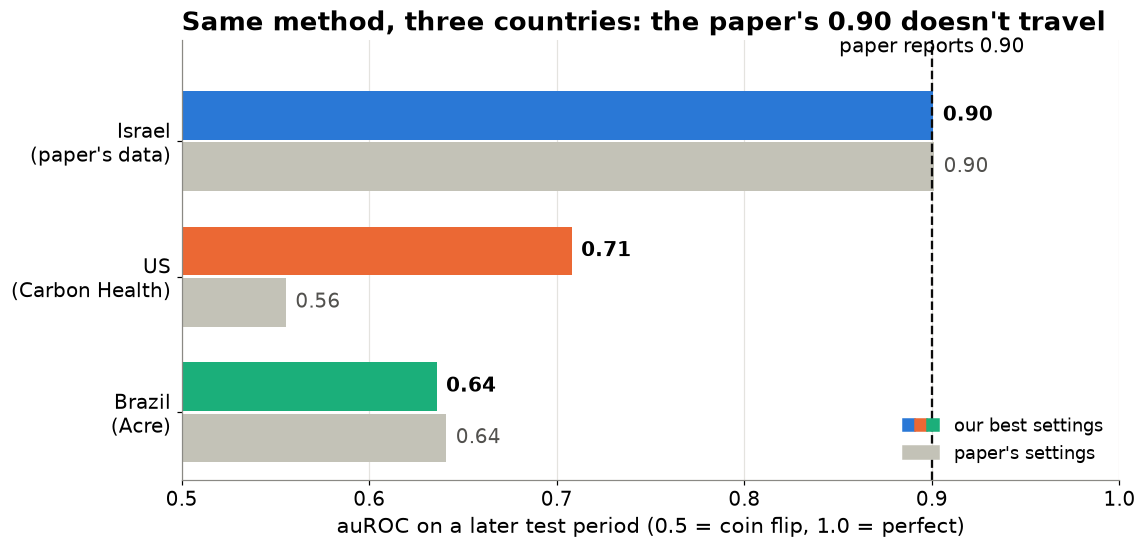

In [169]:
with plt.rc_context(SLIDE_STYLE):
    names = list(SPLITS)
    paper_cfg = within.query("config == 'paper'").set_index("dataset").auroc
    best_cfg = within.query("config == 'best'").set_index("dataset").auroc
    fig, ax = plt.subplots(figsize=(11, 5.2))
    y = np.arange(len(names))
    ax.barh(y + 0.19, paper_cfg[names] - 0.5, left=0.5, height=0.36, color="#c3c2b7", label="paper's settings")
    ax.barh(y - 0.19, best_cfg[names] - 0.5, left=0.5, height=0.36, color=[COLORS[n] for n in names], label="our best settings")
    for i, n in enumerate(names):
        ax.text(paper_cfg[n] + 0.005, i + 0.19, f"{paper_cfg[n]:.2f}", va="center", fontsize=13, color="#52514e")
        ax.text(best_cfg[n] + 0.005, i - 0.19, f"{best_cfg[n]:.2f}", va="center", fontsize=13, fontweight="bold")
    ax.axvline(0.90, color=INK, linestyle="--", linewidth=1.5)
    ax.text(0.90, -0.62, "paper reports 0.90", ha="center", va="bottom", fontsize=13)
    ax.set_yticks(y, [DISPLAY[n] for n in names])
    ax.invert_yaxis()
    ax.set_xlim(0.5, 1.0)
    ax.set_xlabel("auROC on a later test period (0.5 = coin flip, 1.0 = perfect)")
    ax.set_title("Same method, three countries: the paper's 0.90 doesn't travel", loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend([tuple(Patch(color=COLORS[n]) for n in names), Patch(color="#c3c2b7")], ["our best settings", "paper's settings"],
              handler_map={tuple: HandlerTuple(ndivide=None, pad=0)}, frameon=False, loc="lower right")
    ax.set_ylim(len(names) - 0.5, -0.75)
    save(fig, "alternative-datasets", "1_same_method_three_countries")
    plt.show()

### A2. Symptom signal by country

saved assets/alternative-datasets/2_symptom_signal_by_country.png


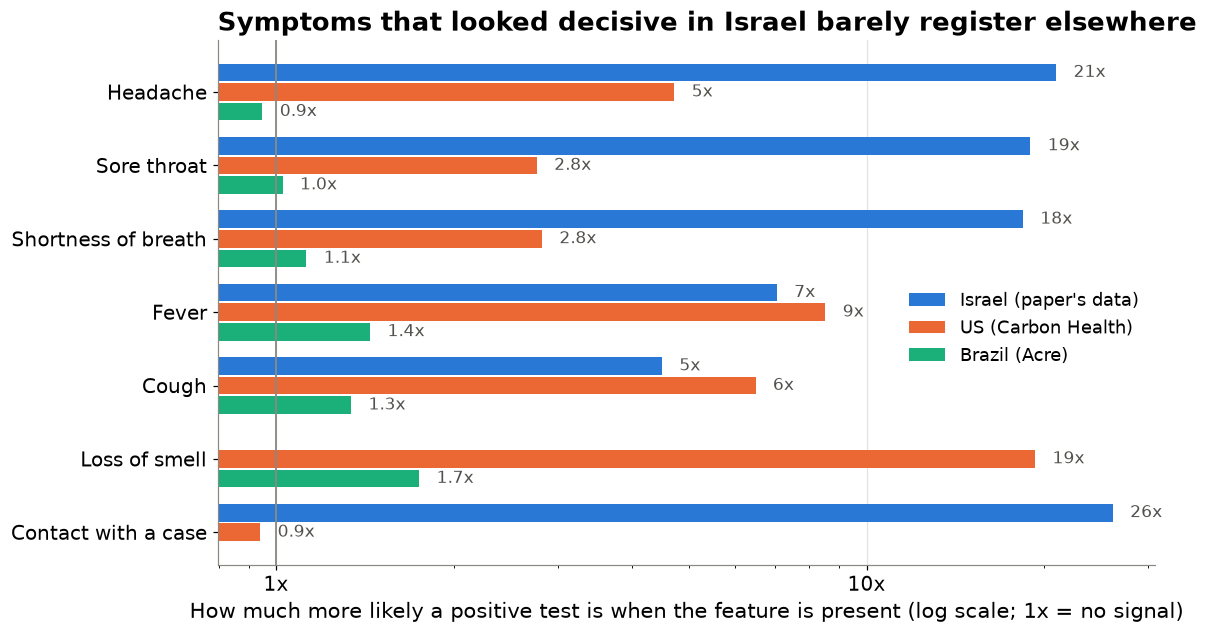

In [170]:
def lift(d, f):
    if f not in sp.available_features(d):
        return np.nan
    return d.loc[d[f] == 1, "y"].mean() / d.loc[d[f] == 0, "y"].mean()

with plt.rc_context(SLIDE_STYLE):
    feats = ["headache", "sore_throat", "shortness_of_breath", "fever", "cough", "loss_of_smell", "contact"]
    nice = {"headache": "Headache", "sore_throat": "Sore throat", "shortness_of_breath": "Shortness of breath",
            "fever": "Fever", "cough": "Cough", "loss_of_smell": "Loss of smell", "contact": "Contact with a case"}
    L = pd.DataFrame({name: {f: lift(d, f) for f in feats} for name, d in DATASETS.items()}).loc[feats]
    fig, ax = plt.subplots(figsize=(11, 6.2))
    n = len(DATASETS)
    h = 0.8 / n
    for j, name in enumerate(DATASETS):
        off = (j - (n - 1) / 2) * h
        ax.barh(np.arange(len(L)) + off, L[name], height=h * 0.9, color=COLORS[name], label=DISPLAY[name].replace("\n", " "))
        for i, v in enumerate(L[name]):
            if pd.notna(v):
                ax.text(v * 1.07, i + off, f"{v:.0f}x" if v >= 3 else f"{v:.1f}x", va="center", fontsize=11, color="#52514e")
    ax.set_xscale("log")
    ax.axvline(1, color=GREY, linewidth=1.2)
    ax.set_yticks(range(len(L)), [nice[f] for f in feats])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}x"))
    ax.set_xlabel("How much more likely a positive test is when the feature is present (log scale; 1x = no signal)")
    ax.set_title("Symptoms that looked decisive in Israel barely register elsewhere", loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, loc="center right", bbox_to_anchor=(1.0, 0.45))
    save(fig, "alternative-datasets", "2_symptom_signal_by_country")
    plt.show()

### A3. Cross-country matrix

saved assets/alternative-datasets/3_cross_country_matrix.png


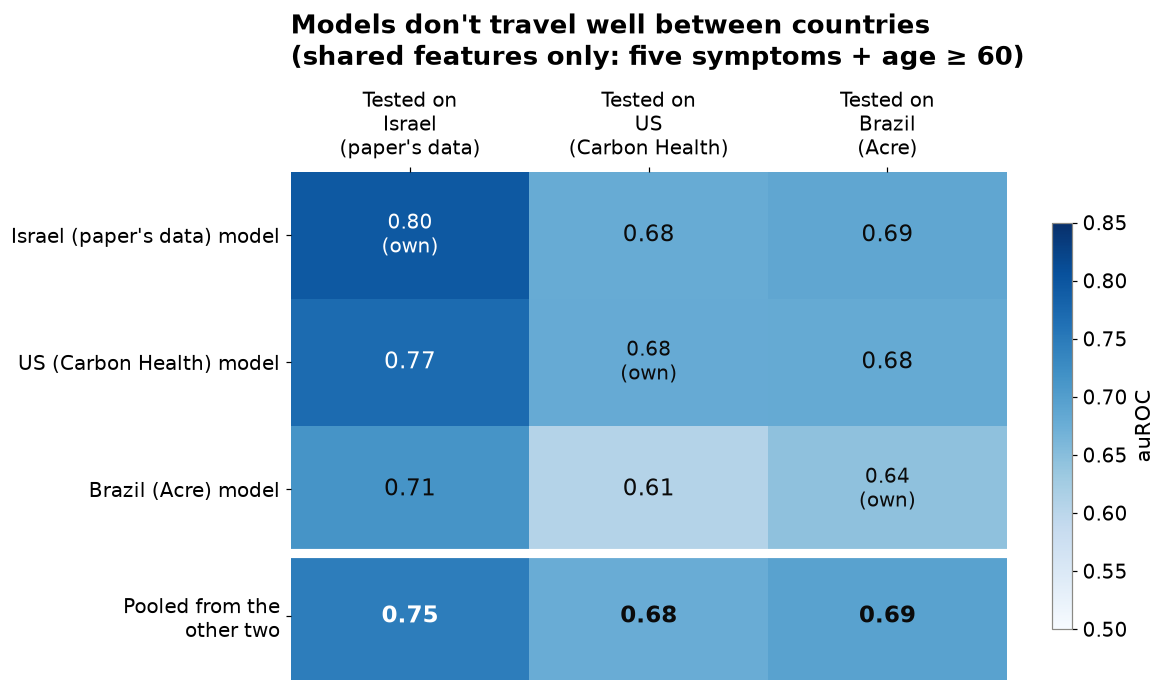

In [171]:
with plt.rc_context(SLIDE_STYLE):
    names = list(DATASETS)
    M = sp.pivot(cross, "auroc").reindex(index=names, columns=names)
    M.loc["pooled"] = loo_common.set_index("held_out").auroc.reindex(names)
    row_labels = [f"{DISPLAY[n]} model".replace("\n", " ") for n in names] + ["Pooled from the\nother two"]
    fig, ax = plt.subplots(figsize=(10.5, 6))
    im = ax.imshow(M.values, cmap="Blues", vmin=0.5, vmax=0.85, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iat[i, j]
            own = i < len(names) and names[i] == names[j]
            ax.text(j, i, f"{v:.2f}" + ("\n(own)" if own else ""), ha="center", va="center", fontsize=15 if not own else 13,
                    fontweight="bold" if i == len(names) else "normal", color="white" if v > 0.72 else INK)
    ax.axhline(len(names) - 0.5, color="white", linewidth=6)
    ax.set_xticks(range(len(names)), [f"Tested on\n{DISPLAY[n]}" for n in names])
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.xaxis.tick_top()
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="auROC")
    ax.set_title("Models don't travel well between countries\n(shared features only: five symptoms + age ≥ 60)", loc="left", pad=70)
    save(fig, "alternative-datasets", "3_cross_country_matrix")
    plt.show()

### A4. A blank field flipped meaning

saved assets/alternative-datasets/4_missing_data_flip.png


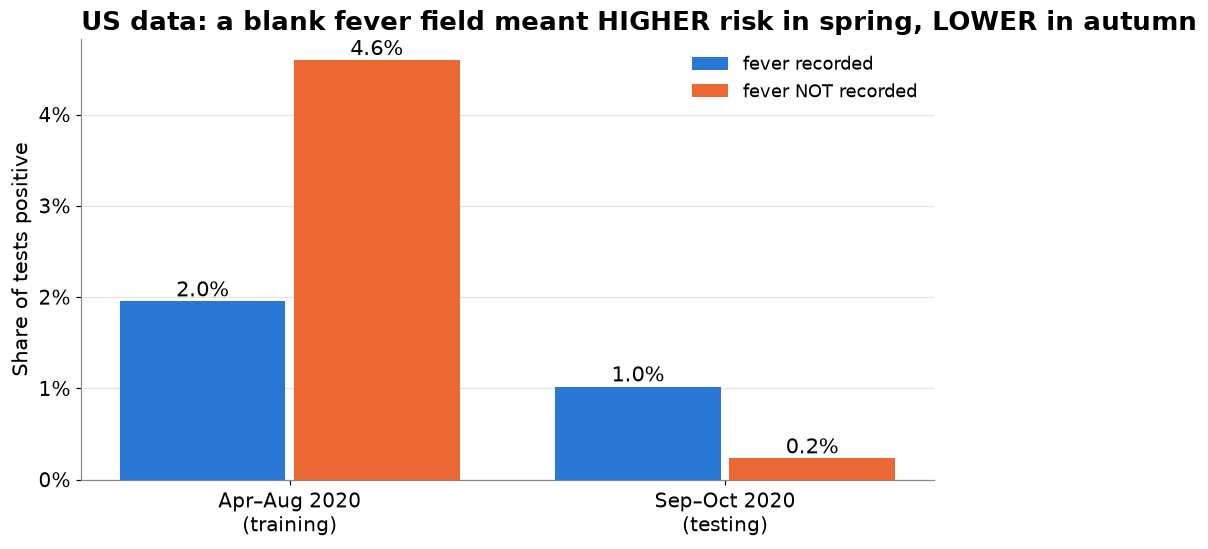

In [172]:
with plt.rc_context(SLIDE_STYLE):
    tr, te = SPLITS["carbon_health"]
    periods = {"Apr–Aug 2020\n(training)": tr, "Sep–Oct 2020\n(testing)": te}
    rec = [d.loc[d.fever.notna(), "y"].mean() for d in periods.values()]
    notrec = [d.loc[d.fever.isna(), "y"].mean() for d in periods.values()]
    fig, ax = plt.subplots(figsize=(10, 5.2))
    x = np.arange(2)
    ax.bar(x - 0.2, rec, width=0.38, color=BLUE, label="fever recorded")
    ax.bar(x + 0.2, notrec, width=0.38, color=ORANGE, label="fever NOT recorded")
    for xi, v in zip(np.r_[x - 0.2, x + 0.2], np.r_[rec, notrec]):
        ax.text(xi, v, f"{v:.1%}", ha="center", va="bottom", fontsize=14)
    ax.set_xticks(x, list(periods))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_ylabel("Share of tests positive")
    ax.set_title("US data: a blank fever field meant HIGHER risk in spring, LOWER in autumn", loc="left")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False)
    save(fig, "alternative-datasets", "4_missing_data_flip")
    plt.show()

### A5. One pooled model for all three countries

saved assets/alternative-datasets/5_pooled_all_countries.png


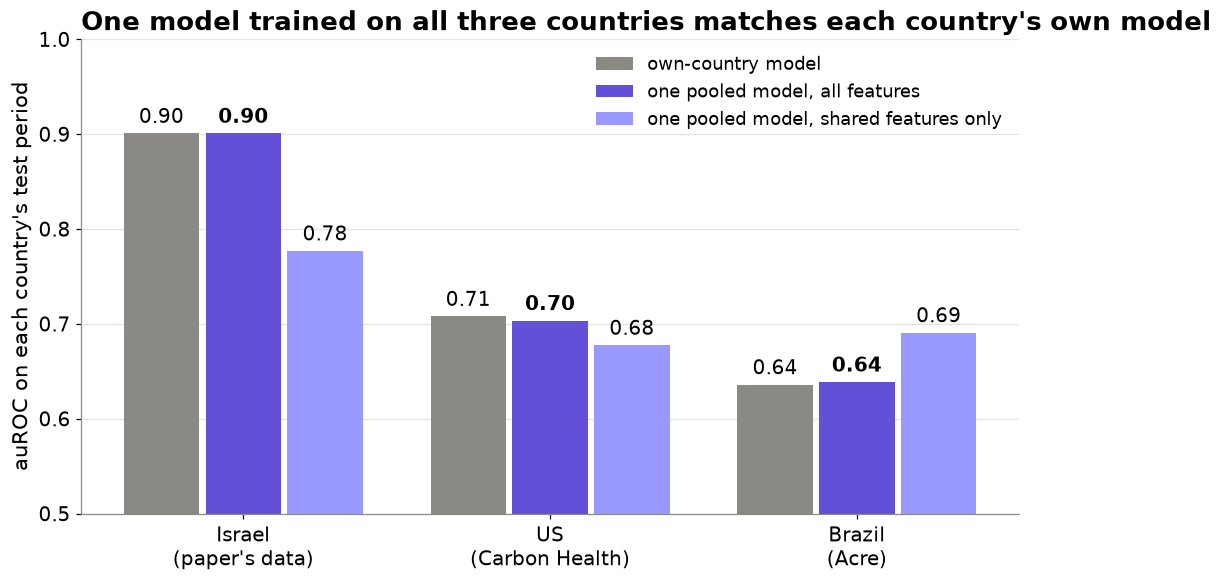

In [173]:
with plt.rc_context(SLIDE_STYLE):
    names = list(SPLITS)
    series = {"own-country model": ("specialist", GREY),
              "one pooled model, all features": ("pooled, all features", "#6250d6"),
              "one pooled model, shared features only": ("pooled, shared features", "#9a99ff")}
    P = pooling.pivot(index="model", columns="test", values="auroc")
    fig, ax = plt.subplots(figsize=(11, 5.6))
    width = 0.8 / len(series)
    for k, (label, (key, color)) in enumerate(series.items()):
        x = np.arange(len(names)) + (k - (len(series) - 1) / 2) * width
        vals = P.loc[key, names].values
        ax.bar(x, vals - 0.5, bottom=0.5, width=width * 0.92, color=color, label=label)
        for xi, v in zip(x, vals):
            ax.text(xi, v + 0.006, f"{v:.2f}", ha="center", va="bottom", fontsize=13,
                    fontweight="bold" if key == "pooled, all features" else "normal")
    ax.set_xticks(range(len(names)), [DISPLAY[n] for n in names])
    ax.set_ylim(0.5, 1.0)
    ax.set_ylabel("auROC on each country's test period")
    ax.set_title("One model trained on all three countries matches each country's own model", loc="left")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, loc="upper right")
    save(fig, "alternative-datasets", "5_pooled_all_countries")
    plt.show()

### A6. Israel's 0.90 leans on contact

saved assets/alternative-datasets/6_contact_ablation.png


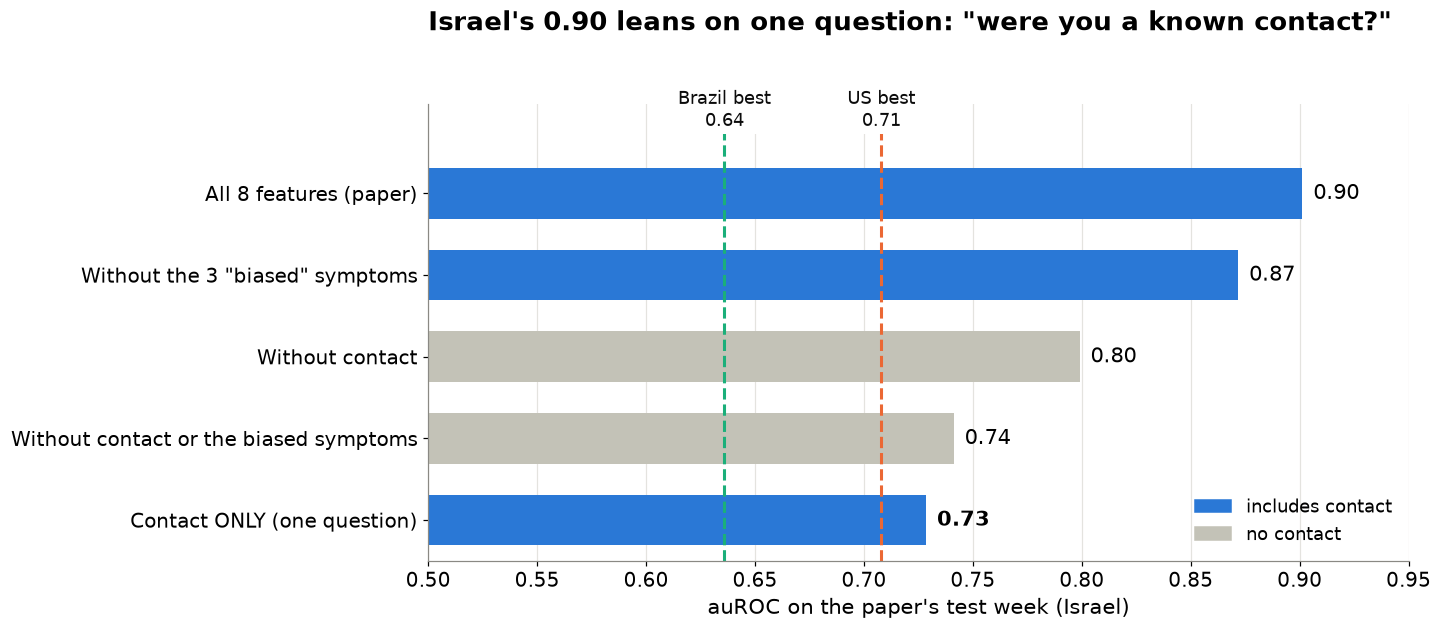

In [174]:
with plt.rc_context(SLIDE_STYLE):
    show = list(ABLATION_SETS)
    nice = {"all 8 (paper)": "All 8 features (paper)", "without the 3 biased symptoms": "Without the 3 \"biased\" symptoms",
            "without contact": "Without contact", "without contact or the 3 biased symptoms": "Without contact or the biased symptoms",
            "contact only": "Contact ONLY (one question)"}
    A = ablation.loc[show]
    has_contact = ["contact" in ABLATION_SETS[s] for s in show]
    fig, ax = plt.subplots(figsize=(11.5, 5.4))
    y = np.arange(len(show))
    ax.barh(y, A.values - 0.5, left=0.5, height=0.62, color=[BLUE if h else "#c3c2b7" for h in has_contact])
    for i, v in enumerate(A.values):
        ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=14, fontweight="bold" if show[i] == "contact only" else "normal")
    best = within.query("config == 'best'").set_index("dataset").auroc
    for label, (v, color) in {"US best": (best["carbon_health"], ORANGE), "Brazil best": (best["brazil"], AQUA)}.items():
        ax.axvline(v, color=color, linestyle="--", linewidth=2)
        ax.text(v, -0.75, f"{label}\n{v:.2f}", ha="center", va="bottom", fontsize=12, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    ax.set_yticks(y, [nice[s] for s in show])
    ax.set_ylim(len(show) - 0.5, -1.1)
    ax.set_xlim(0.5, 0.95)
    ax.set_xlabel("auROC on the paper's test week (Israel)")
    ax.legend(handles=[Patch(color=BLUE, label="includes contact"), Patch(color="#c3c2b7", label="no contact")],
              frameon=False, loc="lower right")
    ax.set_title("Israel's 0.90 leans on one question: \"were you a known contact?\"", loc="left", pad=48)
    ax.grid(axis="y", visible=False)
    save(fig, "alternative-datasets", "6_contact_ablation")
    plt.show()

### A7. How many questions do you need?

saved assets/alternative-datasets/7_how_many_questions.png


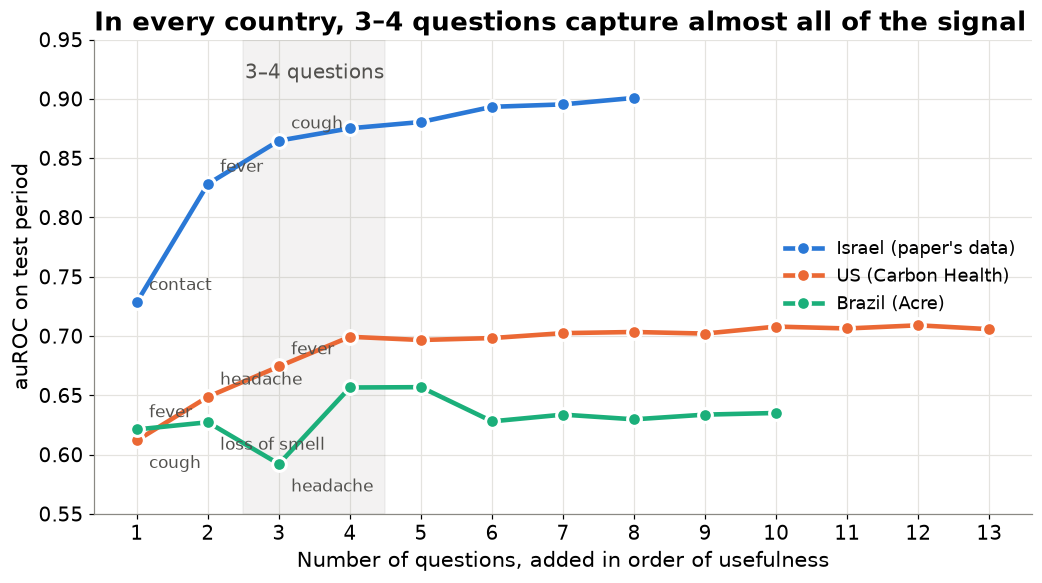

In [175]:
with plt.rc_context(SLIDE_STYLE):
    fig, ax = plt.subplots(figsize=(11, 5.6))
    for name, fs in selection.items():
        ax.plot(fs.step, fs.test_auroc, color=COLORS[name], linewidth=3, marker="o", markersize=9,
                markeredgecolor="white", markeredgewidth=2, label=DISPLAY[name].replace("\n", " "))
        for r in fs.head(3).itertuples():
            ax.annotate(r.added.replace("_", " "), (r.step, r.test_auroc), textcoords="offset points",
                        xytext=(8, 8 if name == "israel" or (name == "brazil") == (r.step == 1) else -18), fontsize=11, color="#52514e")
    ax.axvspan(2.5, 4.5, color=GREY, alpha=0.10)
    ax.text(3.5, 0.93, "3–4 questions", ha="center", va="top", fontsize=13, color="#52514e")
    ax.set_xlabel("Number of questions, added in order of usefulness")
    ax.set_ylabel("auROC on test period")
    ax.set_ylim(0.55, 0.95)
    ax.set_xticks(range(1, max(len(f) for f in selection.values()) + 1))
    ax.set_title("In every country, 3–4 questions capture almost all of the signal", loc="left")
    ax.legend(frameon=False, loc="center right")
    save(fig, "alternative-datasets", "7_how_many_questions")
    plt.show()

---
# B. `alternative-modelling.ipynb` assets → `assets/alternative-modelling/`

### B1. Headroom

saved assets/alternative-modelling/1_headroom.png


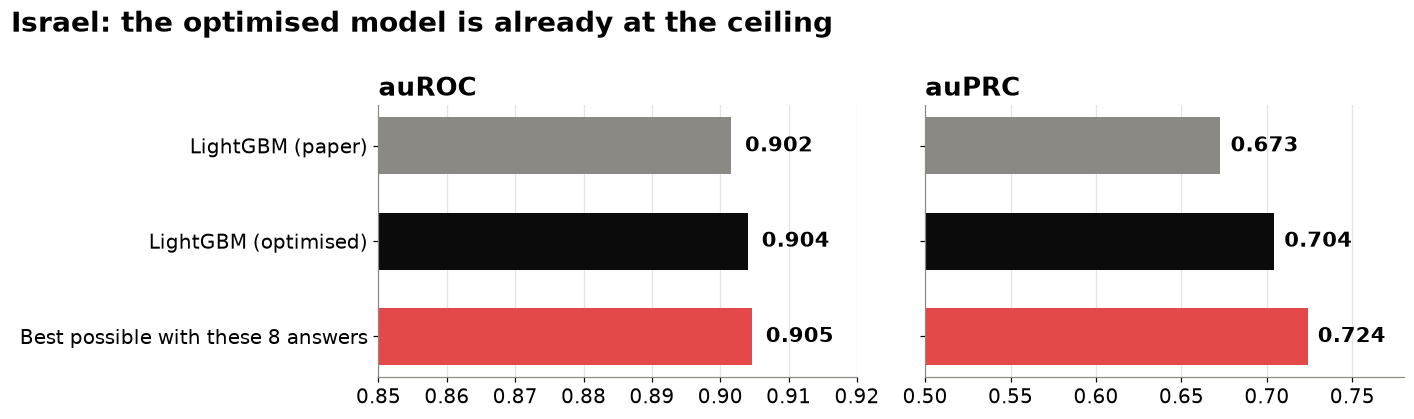

In [176]:
HEADROOM_MODELS = {"LightGBM (paper)": "LightGBM (paper)", "LightGBM (optimised)": "LightGBM (optimised)"}

with plt.rc_context(SLIDE_STYLE):
    S = scores("all 8 features")
    shown = {lab: S.loc[m] for lab, m in HEADROOM_MODELS.items() if m in S.index}
    labels = list(shown) + ["Best possible with these 8 answers"]
    colors = [GREY, INK, "#6250d6", AQUA][:len(shown)] + [RED]
    fig, axes = plt.subplots(1, 2, figsize=(13, 1.3 * len(labels)))
    for ax, metric, key, lo in [(axes[0], "auROC", "auroc", 0.85), (axes[1], "auPRC", "auprc", 0.5)]:
        vals = [r[metric] for r in shown.values()] + [ceilings["all 8 features"][key]]
        ax.barh(range(len(vals)), [v - lo for v in vals], left=lo, color=colors, height=0.6)
        for i, v in enumerate(vals):
            ax.text(v + (0.002 if key == "auroc" else 0.006), i, f"{v:.3f}", va="center", fontsize=14, fontweight="bold")
        ax.set_yticks(range(len(vals)), labels if key == "auroc" else [""] * len(vals))
        ax.invert_yaxis()
        ax.set_xlim(lo, 0.92 if key == "auroc" else 0.78)
        ax.set_title(metric, loc="left")
        ax.grid(axis="y", visible=False)
    fig.suptitle("Israel: the optimised model is already at the ceiling", fontweight="bold", fontsize=18, x=0.01, ha="left")
    fig.tight_layout()
    save(fig, "alternative-modelling", "1_headroom")
    plt.show()

### B2. Leaderboard

Change `LEADERBOARD` to choose the feature set, the models shown, the reference lines and the labels. `leaderboard_chart` is reused by B2b below, so a second variant is one more settings dict.

In [177]:
LEADERBOARD = dict(
    feature_set="all 8 features",      # any key of FEATURE_SETS
    include=None,                      # None = every model with predictions for that feature set; or a list of labels
    exclude=[],                        # labels to leave out
    always_include=[],                 # labels of saved models trained on a different feature set, to show here too
    reference_lines={"LightGBM (paper)": ("LightGBM (paper)", GREY), "LightGBM (optimised)": ("LightGBM (optimised)", INK)},
    rename={},                         # display names, e.g. {"Neural network (MLP)": "Neural net"}
    group_lightgbm=True,               # all LightGBM models in one block at the top, the other techniques below
    title="Model comparison on paper test week",
    xlim_auroc=(0.89, 0.907), xlim_auprc=(0.6, 0.74),
    filename="2_leaderboard",
)

def leaderboard_table(cfg):
    S = scores(cfg["feature_set"])
    extra = [(fs, l) for (fs, l) in zoo if l in cfg["always_include"] and fs != cfg["feature_set"]]
    for fs, l in extra:
        m = sp.metrics(y_test, zoo[(fs, l)])
        S.loc[l] = {"family": sp.FAMILIES.get(l, "saved model file"), "auROC": m["auroc"], "auPRC": m["auprc"]}
    if cfg["include"] is not None:
        S = S.loc[[l for l in cfg["include"] if l in S.index]]
    S = S.drop(index=[l for l in cfg["exclude"] if l in S.index]).sort_values("auROC", ascending=False)
    if cfg.get("group_lightgbm"):
        S = pd.concat([S[[is_lightgbm(l) for l in S.index]], S[[not is_lightgbm(l) for l in S.index]]])
    return S   # top-to-bottom display order

def leaderboard_chart(cfg):
    T = leaderboard_table(cfg)
    ceiling = ceilings[cfg["feature_set"]]
    with plt.rc_context(SLIDE_STYLE):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 0.5 * len(T) + 2.5), sharey=True)
        y = np.arange(len(T))
        n_lgbm = sum(is_lightgbm(l) for l in T.index) if cfg.get("group_lightgbm") else 0
        for ax, metric, ceil, xlim in [(ax1, "auROC", ceiling["auroc"], cfg["xlim_auroc"]),
                                       (ax2, "auPRC", ceiling["auprc"], cfg["xlim_auprc"])]:
            for i, (label, row) in enumerate(T.iterrows()):
                # saved = row.family in ("saved model file", "reported (no model file)")
                saved = False
                # hollow = row.family == "reported (no model file)"
                hollow = False
                ax.scatter(row[metric], i, s=110 if saved else 90, zorder=3, marker="D" if saved else "o",
                           facecolor="white" if hollow else FAMILY_COLORS[row.family],
                           edgecolor=FAMILY_COLORS[row.family], linewidth=2 if hollow else 0)
            if 0 < n_lgbm < len(T):
                ax.axhline(n_lgbm - 0.5, color=GREY, linewidth=1)
            for label, (text, color) in cfg["reference_lines"].items():
                if label in T.index:
                    ax.axvline(T.loc[label, metric], color=color, linestyle="--", linewidth=1.3)
            ax.axvline(ceil, color=RED, linestyle=":", linewidth=2)
            ax.set_xlabel(f"{metric} on the research paper test week")
            ax.set_title(metric, loc="left")
            ax.grid(axis="y", visible=False)
            if xlim:
                ax.set_xlim(*xlim)
            ax.xaxis.set_major_locator(mtick.MaxNLocator(6))
        ax1.set_yticks(y, [cfg["rename"].get(l, l) for l in T.index])
        ax1.set_ylim(len(T) - 0.5, -0.5)
        if 0 < n_lgbm < len(T):
            for yy, text in [(-0.45, "LightGBM"), (n_lgbm - 0.45, "other techniques")]:
                ax1.text(0.01, yy, text, transform=ax1.get_yaxis_transform(), ha="left", va="top", fontsize=11,
                         color="#52514e", style="italic")
        handles = [Line2D([], [], color=c, linestyle="--", label=t) for l, (t, c) in cfg["reference_lines"].items() if l in T.index]
        handles += [Line2D([], [], color=RED, linestyle=":", linewidth=2, label="ceiling (best possible)")]
        # handles += [Line2D([], [], marker="D" if f in ("saved model file", "reported (no model file)") else "o", linestyle="",
        #                    color=FAMILY_COLORS[f], markerfacecolor="white" if f == "reported (no model file)" else FAMILY_COLORS[f],
        handles += [Line2D([], [], marker="o", linestyle="",
                                   color=FAMILY_COLORS[f], markerfacecolor=FAMILY_COLORS[f],
                           markeredgewidth=2, label=f)
                    for f in FAMILY_COLORS if f in set(T.family)]
        fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.12))
        fig.suptitle(cfg["title"], fontweight="bold", fontsize=18, x=0.01, ha="left")
        fig.tight_layout()
        # if "reported (no model file)" in set(T.family):
        #     fig.text(0.01, -0.16, "Hollow diamond: a reported result, measured on a split that also keeps people with unknown "
        #              "sex, with no model file to score here, so only approximately comparable.", fontsize=11, color="#52514e")
        save(fig, "alternative-modelling", cfg["filename"])
        plt.show()
    return T

leaderboard_chart(LEADERBOARD).style.format({"auROC": "{:.4f}", "auPRC": "{:.4f}"})

KeyError: 'saved model file'

### B2b. Leaderboard without the biased symptoms

The same chart for models trained on the 5 features left once sore throat, shortness of breath and headache are removed. The optimised LightGBM for these 5 features has a reported result but no model file yet, so it's shown as a hollow diamond. Add the file to `SAVED_MODELS` when it's available.

saved assets/alternative-modelling/2b_leaderboard_without_biased_symptoms.png


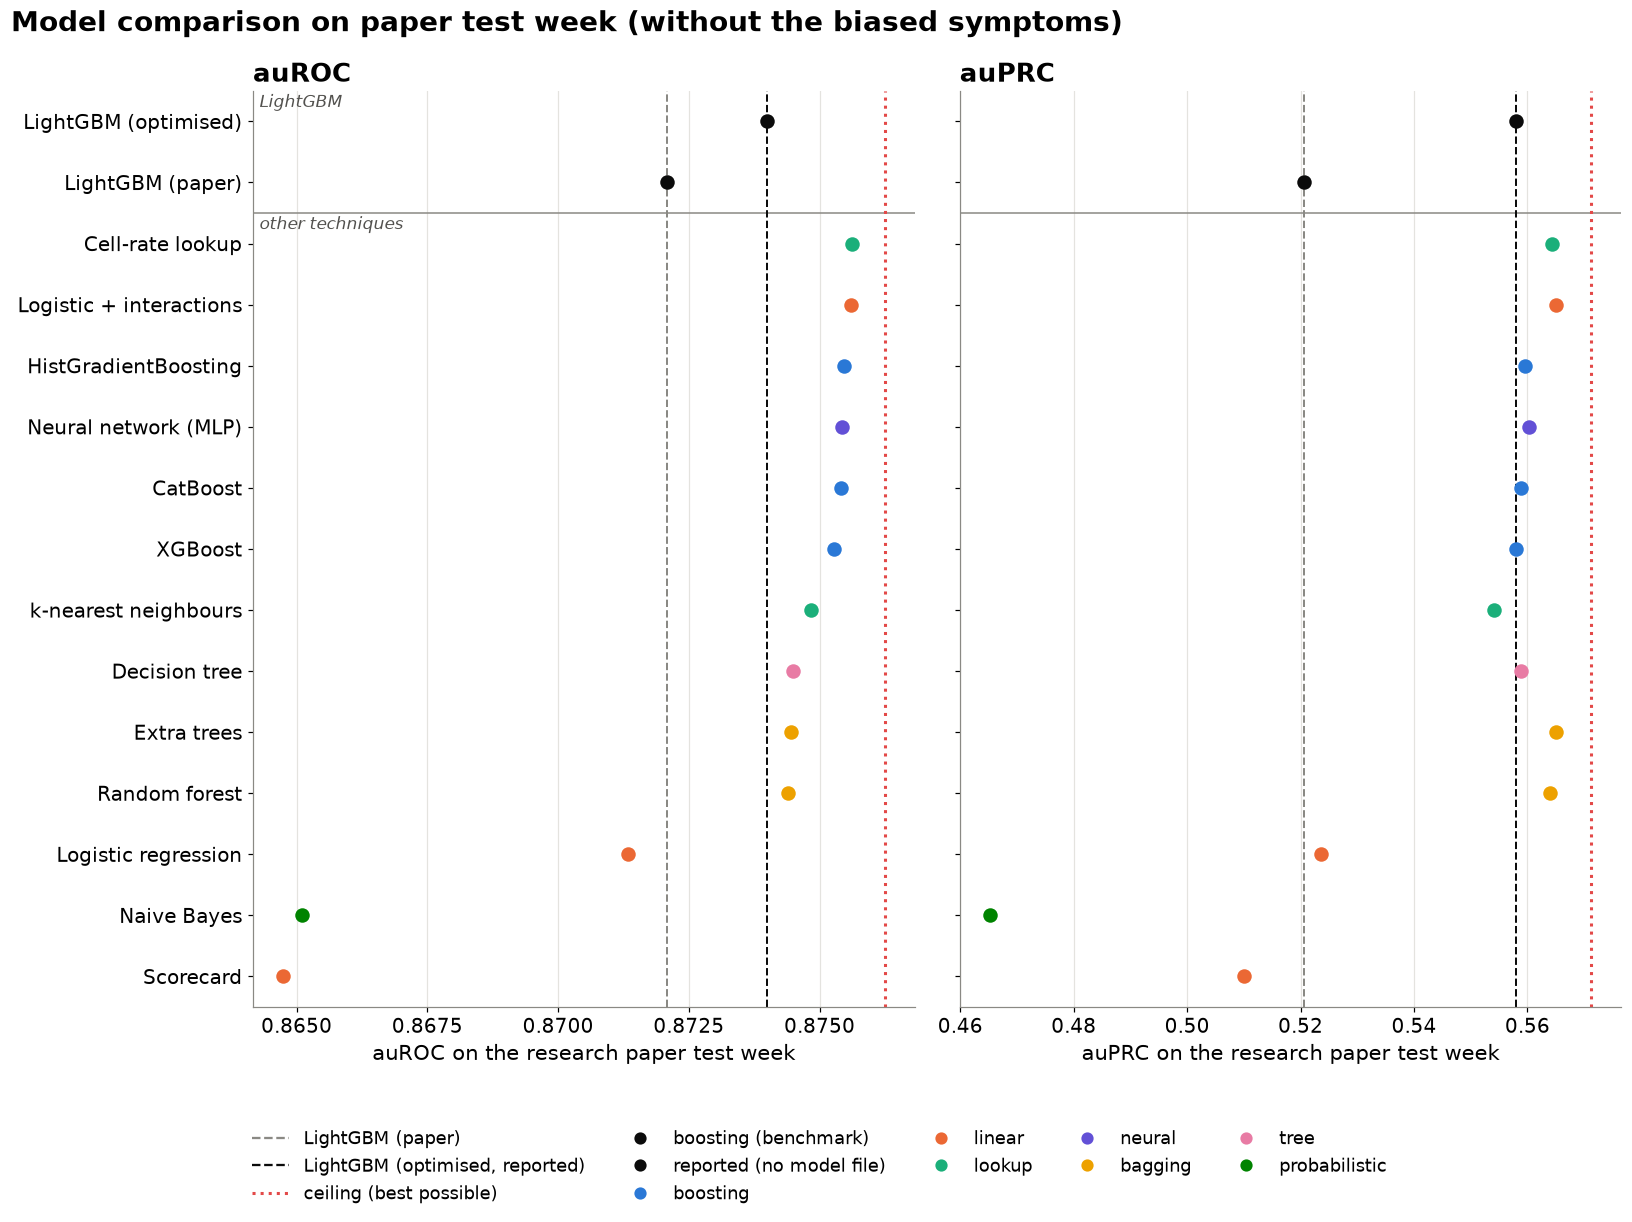

,family,auROC,auPRC
LightGBM (optimised),reported (no model file),0.8740,0.5580
LightGBM (paper),boosting (benchmark),0.8721,0.5206
Cell-rate lookup,lookup,0.8756,0.5644
Logistic + interactions,linear,0.8756,0.5651
HistGradientBoosting,boosting,0.8755,0.5595
Neural network (MLP),neural,0.8754,0.5602
CatBoost,boosting,0.8754,0.5588
XGBoost,boosting,0.8753,0.5580
k-nearest neighbours,lookup,0.8748,0.5542
Decision tree,tree,0.8745,0.5589


In [ ]:
LEADERBOARD_NO_BIASED = dict(
    LEADERBOARD,
    feature_set="without the 3 biased symptoms",
    exclude=[],
    reference_lines={"LightGBM (paper)": ("LightGBM (paper)", GREY),
                     "LightGBM (optimised)": ("LightGBM (optimised, reported)", INK)},
    title="Model comparison on paper test week (without the biased symptoms)",
    xlim_auroc=None, xlim_auprc=None,
    filename="2b_leaderboard_without_biased_symptoms",
)
leaderboard_chart(LEADERBOARD_NO_BIASED).style.format({"auROC": "{:.4f}", "auPRC": "{:.4f}"})

### B3. Bias check

`BIAS_MODELS` sets which models appear. A saved model appears only under the feature set it was trained on.

saved assets/alternative-modelling/3_bias_check.png


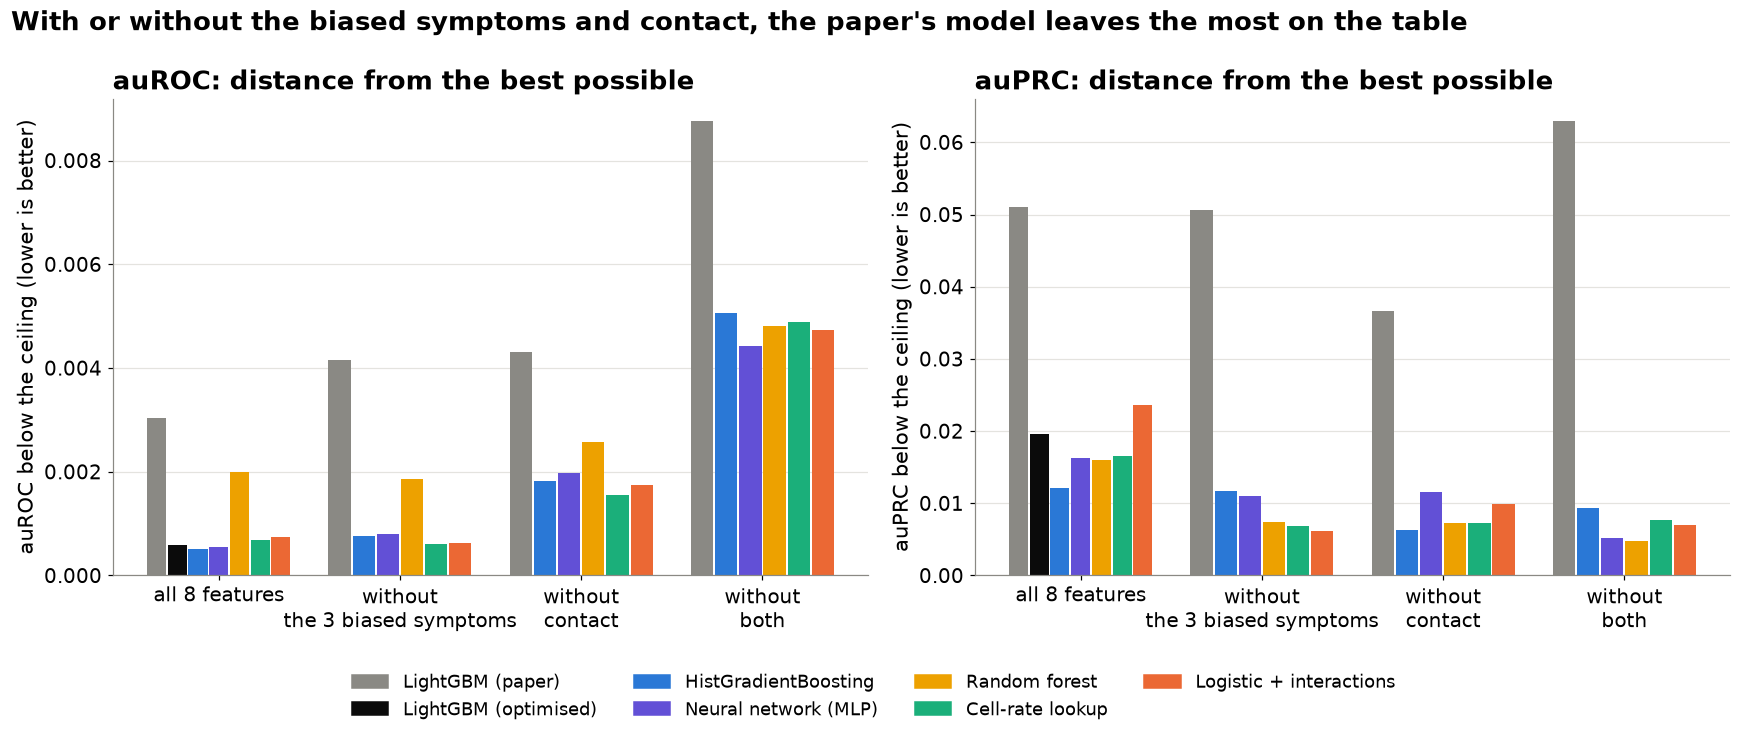

In [ ]:
# LightGBM models first, together. Saved files only have bars for the feature set they were trained on.
BIAS_MODELS = ["LightGBM (paper)", "LightGBM (optimised)", *ALTERNATIVES]
BIAS_COLORS = {"LightGBM (paper)": GREY, "LightGBM (optimised)": INK}

def gap_to_ceiling(fs, label, key):
    p = zoo.get((fs, label))
    return np.nan if p is None else ceilings[fs][key] - sp.metrics(y_test, p)[key]

with plt.rc_context(SLIDE_STYLE):
    sets = list(FEATURE_SETS)
    colors = {m: BIAS_COLORS.get(m, FAMILY_COLORS.get(sp.FAMILIES.get(m, ""), GREY)) for m in BIAS_MODELS}
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, metric, key in zip(axes, ["auROC", "auPRC"], ["auroc", "auprc"]):
        for i, fs in enumerate(sets):
            present = [m for m in BIAS_MODELS if (fs, m) in zoo]   # only models with a result here, packed together
            width = 0.8 / max(len(present), 1)
            for j, m in enumerate(present):
                ax.bar(i + (j - (len(present) - 1) / 2) * width, gap_to_ceiling(fs, m, key), width * 0.92, color=colors[m])
        ax.set_xticks(range(len(sets)), [s.replace("without ", "without\n") for s in sets])
        ax.set_ylabel(f"{metric} below the ceiling (lower is better)")
        ax.set_title(f"{metric}: distance from the best possible", loc="left")
        ax.grid(axis="x", visible=False)
    shown = [m for m in BIAS_MODELS if any((fs, m) in zoo for fs in sets)]
    handles, labels = [Patch(color=colors[m]) for m in shown], shown
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle("With or without the biased symptoms and contact, the paper's model leaves the most on the table",
                 fontweight="bold", fontsize=17, x=0.01, ha="left")
    fig.tight_layout()
    save(fig, "alternative-modelling", "3_bias_check")
    plt.show()

### B4. Pooling, technique by country

saved assets/alternative-modelling/4_pooling_by_technique.png


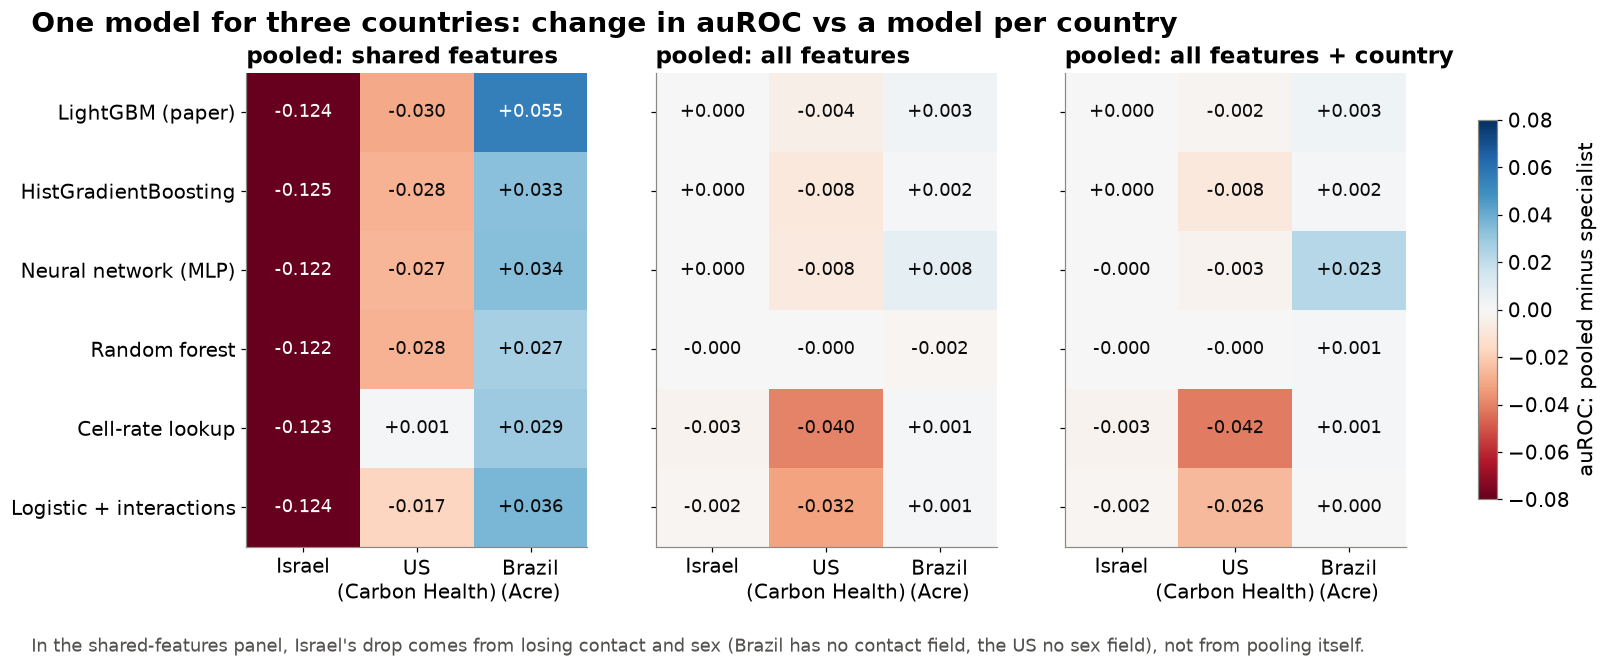

In [ ]:
VARIANTS = ["pooled, shared features", "pooled, all features", "pooled, all features + country"]
pvs_all = pd.concat([r.assign(technique=name) for name, r in pvs.items()], ignore_index=True)

def by_country(variant):
    t = pvs_all[pvs_all["model"] == variant].pivot(index="technique", columns="test", values="auroc")
    return t.reindex(index=CROSS_MODELS, columns=list(SPLITS))

pool_delta = {v: by_country(v) - by_country("specialist") for v in VARIANTS}
with plt.rc_context(SLIDE_STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), sharey=True)
    for ax, v in zip(axes, VARIANTS):
        d = pool_delta[v]
        im = ax.imshow(d.values, cmap="RdBu", vmin=-0.08, vmax=0.08, aspect="auto")
        for i in range(d.shape[0]):
            for j in range(d.shape[1]):
                ax.text(j, i, f"{d.iloc[i, j]:+.3f}", ha="center", va="center", fontsize=12,
                        color="white" if abs(d.iloc[i, j]) > 0.05 else INK)
        ax.set_xticks(range(d.shape[1]), [DISPLAY[c].replace("(paper's data)", "").strip() for c in d.columns])
        ax.set_yticks(range(d.shape[0]), d.index)
        ax.set_title(v.replace("pooled, ", "pooled: "), loc="left", fontsize=15)
        ax.grid(False)
    fig.colorbar(im, ax=axes, shrink=0.8, label="auROC: pooled minus specialist")
    fig.text(0.01, -0.06, "In the shared-features panel, Israel's drop comes from losing contact and sex (Brazil has no contact field, "
             "the US no sex field), not from pooling itself.", fontsize=12, color="#52514e")
    fig.suptitle("One model for three countries: change in auROC vs a model per country", fontweight="bold",
                 fontsize=18, x=0.01, ha="left")
    save(fig, "alternative-modelling", "4_pooling_by_technique")
    plt.show()

### B5. A never-seen country

saved assets/alternative-modelling/5_unseen_country.png


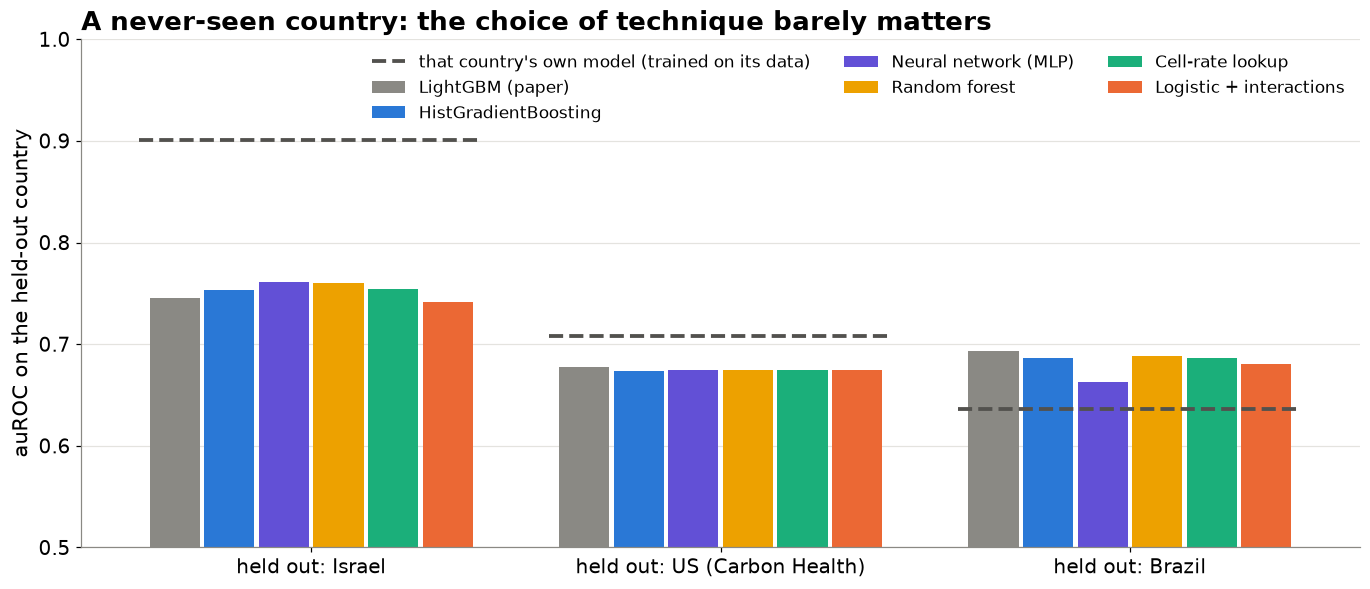

In [ ]:
with plt.rc_context(SLIDE_STYLE):
    names = list(SPLITS)
    specialists = by_country("specialist")
    width = 0.8 / len(CROSS_MODELS)
    colors = {"LightGBM (paper)": GREY}
    colors.update({m: FAMILY_COLORS[sp.FAMILIES[m]] for m in CROSS_MODELS if m not in colors})
    fig, ax = plt.subplots(figsize=(15, 6))
    for j, m in enumerate(CROSS_MODELS):
        vals = loo_shared[m].set_index("held_out").loc[names, "auroc"]
        ax.bar(np.arange(len(names)) + (j - (len(CROSS_MODELS) - 1) / 2) * width, vals - 0.5, width * 0.92,
               bottom=0.5, color=colors[m], label=m)
    for i, n in enumerate(names):
        ax.plot([i - 0.42, i + 0.42], [specialists.loc["LightGBM (paper)", n]] * 2, color="#52514e", linewidth=2.5,
                linestyle="--", label="that country's own model (trained on its data)" if i == 0 else None)
    ax.set_xticks(range(len(names)), [f"held out: {DISPLAY[n].splitlines()[0]}" + (" (Carbon Health)" if n == "carbon_health" else "")
                                      for n in names])
    ax.set_ylim(0.5, 1.0)
    ax.set_ylabel("auROC on the held-out country")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, ncol=3, loc="upper right", fontsize=11)
    ax.set_title("A never-seen country: the choice of technique barely matters", loc="left")
    save(fig, "alternative-modelling", "5_unseen_country")
    plt.show()